# Домашнее задание 3. Анализ данных сервиса такси

Темы лекций 11-17: NumPy, pandas, чистка данных, объединение таблиц, группировка, визуализация.

Сервис вызова такси предоставил выгрузку поездок за первый квартал 2024 года. Данные сырые, прямо из системы. Проведите анализ и ответьте на 10 вопросов. Каждый вопрос имеет один верный ответ. Выполните расчёт в этом ноутбуке, затем введите ответы в поля на странице задания на платформе.

Данные загружаются напрямую по ссылке, скачивать отдельно не нужно. Прежде чем считать любую цифру, осмотрите данные: типы столбцов, дубликаты, пропуски, форматы записи.

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

trips = pd.read_csv("hw3_trips.csv")
drivers = pd.read_csv("hw3_drivers.csv")

# Приведение статуса к нижнему регистру
trips['status'] = trips['status'].str.lower()

# Очистка fare_uzs: удаляем всё, кроме цифр и точки
trips['fare_uzs'] = trips['fare_uzs'].astype(str).str.replace(r'[^\d.]', '', regex=True)
trips['fare_uzs'] = pd.to_numeric(trips['fare_uzs'], errors='coerce')

# Удаление полных дубликатов
trips_unique = trips.drop_duplicates()

print(trips.shape, drivers.shape)
trips.head()



(5080, 11) (300, 5)


,trip_id,datetime,city,driver_id,distance_km,duration_min,surge_multiplier,fare_uzs,status,payment_method,rating
0,T004702,2024-02-02 10:30:00,Toshkent,D0244,3.9,11.0,1.0,10800.0,completed,cash,5.0
1,T000766,2024-02-18 08:46:00,Samarqand,D0011,2.3,5.0,1.0,8400.0,completed,card,4.0
2,T002639,2024-01-26 01:51:00,Toshkent,D0215,14.9,43.0,1.0,27400.0,completed,card,4.5
3,T004022,2024-03-17 19:43:00,Andijon,D0240,3.1,10.0,1.3,19300.0,completed,card,3.8
4,T001096,2024-02-12 18:38:00,Samarqand,D0117,5.0,11.0,2.0,38000.0,completed,card,3.8


## Q1. Объём данных

В выгрузке есть полные дубликаты строк. Сколько уникальных поездок остаётся после их удаления? Введите целое число.

In [22]:
trips_unique = trips.drop_duplicates()
q1 = len(trips_unique)
print(f"Q1: {q1}")

Q1: 5000


## Q2. Выручка

Какова суммарная выручка по завершённым поездкам, в миллионах UZS (округлите до целого)?

Учтите: столбец `fare_uzs` записан текстом с пробелами, а в столбце `status` один и тот же статус встречается в разном регистре.

In [23]:
completed = trips_unique[trips_unique['status'] == 'completed']
total_fare = completed['fare_uzs'].sum()
q2 = round(total_fare / 1_000_000)
print(f"Q2: {q2} млн UZS")

Q2: 86 млн UZS


## Q3. Аномальные тарифы

Среди завершённых поездок, сколько имеют тариф выше `mean + 2 * std`? Используйте NumPy (`np.mean`, `np.std`). Введите целое число.

In [24]:
fare_vals = completed['fare_uzs'].dropna()
mean_fare = np.mean(fare_vals)
std_fare = np.std(fare_vals)
threshold = mean_fare + 2 * std_fare
q3 = (fare_vals > threshold).sum()
print(f"Q3: {q3}")

Q3: 207


## Q4. Час пик

В какой час суток (0-23) совершается больше всего поездок? Постройте линейный график числа поездок по часам и определите пик.

Q4: 18


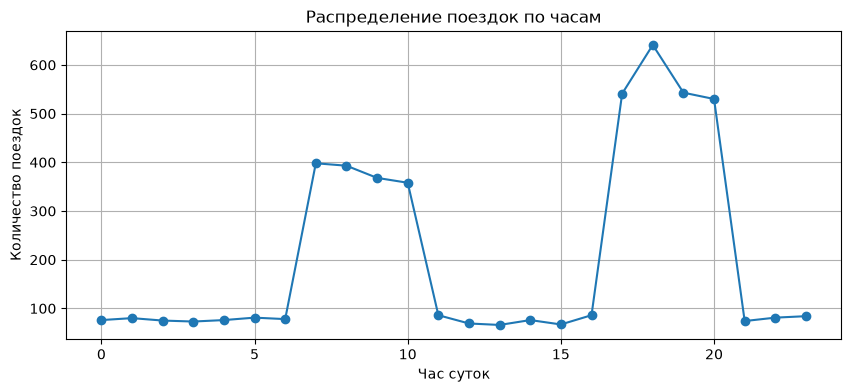

In [25]:
trips_unique['hour'] = pd.to_datetime(trips_unique['datetime']).dt.hour
hourly_counts = trips_unique['hour'].value_counts().sort_index()
peak_hour = hourly_counts.idxmax()
print(f"Q4: {peak_hour}")

plt.figure(figsize=(10,4))
plt.plot(hourly_counts.index, hourly_counts.values, marker='o')
plt.xlabel('Час суток')
plt.ylabel('Количество поездок')
plt.title('Распределение поездок по часам')
plt.grid()
plt.show()

## Q5. Город-лидер

В каком городе наибольшая суммарная выручка по завершённым поездкам? Введите название города как в данных.

In [26]:
city_revenue = completed.groupby('city')['fare_uzs'].sum()
q5 = city_revenue.idxmax()
print(f"Q5: {q5}")

Q5: Toshkent


## Q6. Класс автомобиля

Объедините поездки с таблицей водителей по `driver_id`. У какого класса автомобиля самый высокий средний тариф (по завершённым поездкам)? Введите название класса.

In [27]:
merged = completed.merge(drivers, on='driver_id', how='left')
avg_fare_by_class = merged.groupby('vehicle_class')['fare_uzs'].mean()
q6 = avg_fare_by_class.idxmax()
print(f"Q6: {q6}")

Q6: Business


## Q7. Отмены

Какова доля отменённых поездок (статус `cancelled`) среди всех поездок, в процентах (округлите до целого)? Учтите разный регистр в статусе.

In [28]:
total = len(trips_unique)
cancelled = (trips_unique['status'] == 'cancelled').sum()
q7 = round(cancelled / total * 100)
print(f"Q7: {q7}%")

Q7: 10%


## Q8. Скорость

Какова медианная скорость поездки в км/ч? Скорость = `distance_km / duration_min * 60`. Перед расчётом уберите поездки с нулевой или отрицательной дистанцией и с пропущенной длительностью.

In [29]:
speed_data = trips_unique[
    (trips_unique['distance_km'] > 0) &
    (trips_unique['duration_min'].notna())
].copy()
speed_data['speed'] = speed_data['distance_km'] / speed_data['duration_min'] * 60
q8 = speed_data['speed'].median()
print(f"Q8: {q8:.2f} км/ч")

Q8: 26.00 км/ч


## Q9. Способ оплаты

Какой способ оплаты используется чаще всего среди завершённых поездок? Постройте столбчатую диаграмму. Введите значение как в данных.

Q9: card


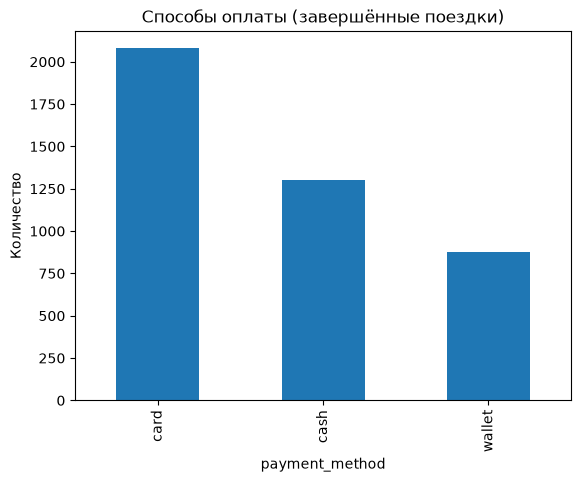

In [30]:
payment_counts = completed['payment_method'].value_counts()
q9 = payment_counts.idxmax()
print(f"Q9: {q9}")

payment_counts.plot(kind='bar')
plt.title('Способы оплаты (завершённые поездки)')
plt.ylabel('Количество')
plt.show()

## Q10. Длина поездки

Чему равен 90-й перцентиль дистанции поездки (км, округлите до целого)? Используйте только поездки с корректной дистанцией (больше нуля).

In [ ]:

# 2. Приводим distance_km к числовому типу (нечисловые -> NaN)
trips_unique['distance_km'] = pd.to_numeric(trips_unique['distance_km'], errors='coerce')

# 3. Оставляем только положительные расстояния
valid_dist = trips_unique[trips_unique['distance_km'] > 0]['distance_km']

# 4. Вычисляем 90-й перцентиль и округляем по математическим правилам
q10 = int(round(np.percentile(valid_dist, 90)))

print(f"90-й перцентиль = {q10} км")

90-й перцентиль = 11 км


## Отправка ответов

Перенесите полученные значения в поля на странице задания на платформе и отправьте до дедлайна.